In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url =  "https://ourworldindata.org/grapher/annual-co2-emissions-per-country.csv"

df = pd.read_csv(url)

print ("Dataset loaded successfully!")
print ("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (29384, 4)

Column names:
['Entity', 'Code', 'Year', 'Annual CO₂ emissions']


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,84272.0
2,Afghanistan,AFG,1951,91600.0
3,Afghanistan,AFG,1952,91600.0
4,Afghanistan,AFG,1953,106256.0


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nYear range:")
print(df["Year"].min(), "to", df['Year'].max())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29384 entries, 0 to 29383
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                29384 non-null  object 
 1   Code                  26073 non-null  object 
 2   Year                  29384 non-null  int64  
 3   Annual CO₂ emissions  29384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 918.4+ KB

Missing values in each column:
Entity                     0
Code                    3311
Year                       0
Annual CO₂ emissions       0
dtype: int64

Year range:
1750 to 2024


In [6]:
print(df.head())
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

        Entity Code  Year  Annual CO₂ emissions
0  Afghanistan  AFG  1949               14656.0
1  Afghanistan  AFG  1950               84272.0
2  Afghanistan  AFG  1951               91600.0
3  Afghanistan  AFG  1952               91600.0
4  Afghanistan  AFG  1953              106256.0

Column names:
['Entity', 'Code', 'Year', 'Annual CO₂ emissions']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29384 entries, 0 to 29383
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                29384 non-null  object 
 1   Code                  26073 non-null  object 
 2   Year                  29384 non-null  int64  
 3   Annual CO₂ emissions  29384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 918.4+ KB


In [7]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nYear range:")
print(df["Year"].min(), "to", df["Year"].max())

print("\nNumber of unique countries/entities:")
print(df["Entity"].nunique())

Missing values:
Entity                     0
Code                    3311
Year                       0
Annual CO₂ emissions       0
dtype: int64

Duplicate rows: 0

Year range:
1750 to 2024

Number of unique countries/entities:
247


In [11]:
#identify the emission column automatically
emissions_col = next(
    col for col in df.columns
    if "emissions" in col.lower()
)

#select the countries for comparison
countries = ["Malaysia", "Indonesia", "Thailand", "Singapore"]

analysis_df = df [
    df["Entity"].isin(countries)
][["Entity", "Year", emissions_col]].copy()

#remove observations missing essential analysis values
analysis_df = analysis_df.dropna(
    subset=["Entity", "Year", emissions_col]
)

#keep one observation per country per year
analysis_df = analysis_df.drop_duplicates(
    subset=["Entity", "Year"]
)

analysis_df["Year"] = analysis_df["Year"].astype(int)

analysis_df = analysis_df.sort_values(
    ["Entity", "Year"]
)

print("Cleaned dataset:")
print(analysis_df.head(10))

print("\nObservations by country:")
print(analysis_df.groupby("Entity").size())

Cleaned dataset:
          Entity  Year  Annual CO₂ emissions
13028  Indonesia  1889                3664.0
13029  Indonesia  1890               14656.0
13030  Indonesia  1891               21984.0
13031  Indonesia  1892              190757.0
13032  Indonesia  1893              403040.0
13033  Indonesia  1894              479984.0
13034  Indonesia  1895              769440.0
13035  Indonesia  1896              861040.0
13036  Indonesia  1897             1106528.0
13037  Indonesia  1898             1289728.0

Observations by country:
Entity
Indonesia    136
Malaysia     134
Singapore     75
Thailand      91
dtype: int64


In [12]:
analysis_df["YoY_change_percent"] = (
    analysis_df.groupby("Entity")[emissions_col]
    .pct_change() * 100
)

# Show the latest available observation for each country
latest = (
    analysis_df.sort_values("Year")
    .groupby("Entity")
    .tail(1)
    [["Entity", "Year", emissions_col, "YoY_change_percent"]]
)

print(latest.to_string(index=False))

   Entity  Year  Annual CO₂ emissions  YoY_change_percent
Indonesia  2024           812220200.0            6.540583
 Malaysia  2024           290223840.0            5.040620
 Thailand  2024           267760200.0            1.143232
Singapore  2024            53919460.0            5.584447


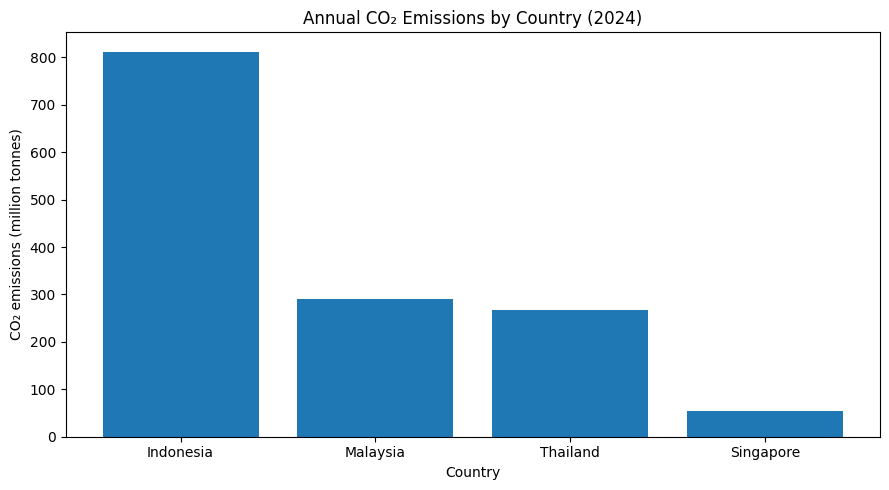

In [13]:

latest = (
    analysis_df.sort_values("Year")
    .groupby("Entity")
    .tail(1)
)

latest = latest.sort_values(emissions_col, ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(
    latest["Entity"],
    latest[emissions_col] / 1_000_000
)

plt.title("Annual CO₂ Emissions by Country (2024)")
plt.xlabel("Country")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.tight_layout()
plt.show()


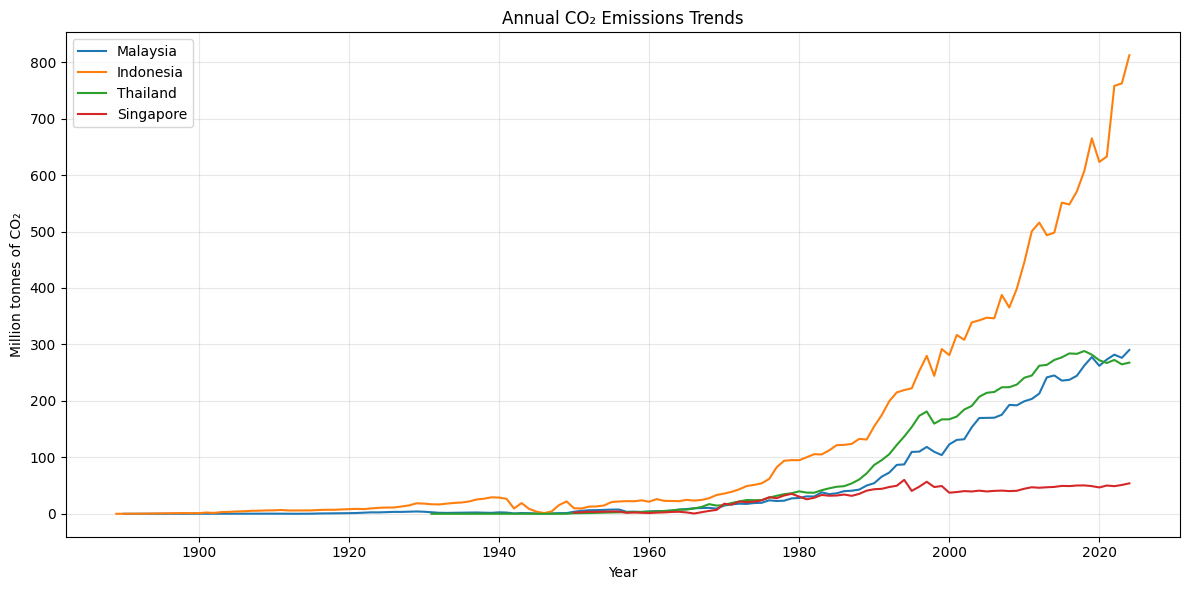

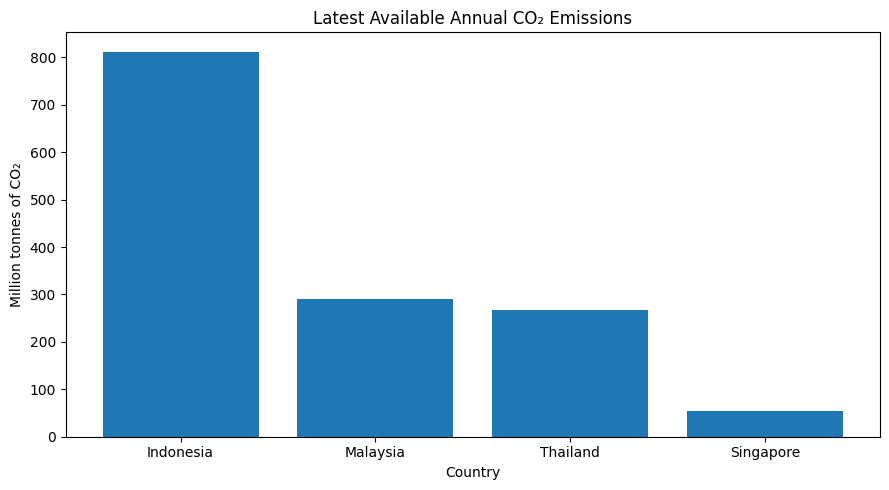

Charts saved successfully!


In [16]:

import os

os.makedirs("figures", exist_ok=True)

# Save the trend chart
plt.figure(figsize=(12, 6))

for country in countries:
    country_data = analysis_df[
        analysis_df["Entity"] == country
    ]
    plt.plot(
        country_data["Year"],
        country_data[emissions_col] / 1_000_000,
        label=country
    )

plt.title("Annual CO₂ Emissions Trends")
plt.xlabel("Year")
plt.ylabel("Million tonnes of CO₂")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/emissions_trends.png", dpi=300)
plt.show()

# Save the latest-year comparison chart
plt.figure(figsize=(9, 5))
plt.bar(
    latest_summary["Entity"],
    latest_summary["Emissions_million_tonnes"]
)
plt.title("Latest Available Annual CO₂ Emissions")
plt.xlabel("Country")
plt.ylabel("Million tonnes of CO₂")
plt.tight_layout()
plt.savefig("figures/latest_emissions_comparison.png", dpi=300)
plt.show()

print("Charts saved successfully!")


In [19]:
# Filter Malaysia's data to 1990–2024
malaysia_recent = malaysia[
    (malaysia["Year"] >= 1990) &
    (malaysia["Year"] <= 2024)
].sort_values("Year")

# Get the first and last observations in this period
first = malaysia_recent.iloc[0]
last = malaysia_recent.iloc[-1]

start_emissions = first[emissions_col]
end_emissions = last[emissions_col]

absolute_change = end_emissions - start_emissions
percentage_change = (absolute_change / start_emissions) * 100

print(f"Starting year: {first['Year']}")
print(f"Starting emissions: {start_emissions:,.0f} tonnes")
print(f"Ending year: {last['Year']}")
print(f"Ending emissions: {end_emissions:,.0f} tonnes")
print(f"Absolute change: {absolute_change:,.0f} tonnes")
print(f"Percentage change: {percentage_change:.2f}%")

Starting year: 1990
Starting emissions: 54,269,364 tonnes
Ending year: 2024
Ending emissions: 290,223,840 tonnes
Absolute change: 235,954,476 tonnes
Percentage change: 434.78%


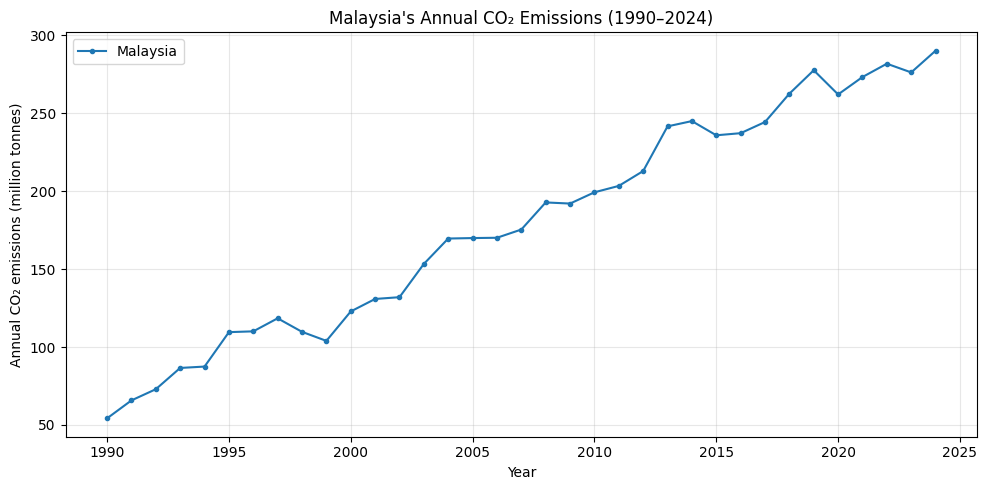

In [20]:

plt.figure(figsize=(10, 5))

plt.plot(
    malaysia_recent["Year"],
    malaysia_recent[emissions_col] / 1_000_000,
    marker="o",
    markersize=3,
    label="Malaysia"
)

plt.title("Malaysia's Annual CO₂ Emissions (1990–2024)")
plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (million tonnes)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("malaysia_emissions_1990_2024.png", dpi=300)
plt.show()


In [26]:

# Select emissions data from 1990 to 2024
recent_df = analysis_df[
    (analysis_df["Year"] >= 1990) &
    (analysis_df["Year"] <= 2024)
].copy()

# Find the first and latest available year for each country
comparison = (
    recent_df.sort_values(["Entity", "Year"])
    .groupby("Entity")
    .agg(
        Starting_year=("Year", "first"),
        Starting_emissions=(emissions_col, "first"),
        Ending_year=("Year", "last"),
        Ending_emissions=(emissions_col, "last")
    )
    .reset_index()
)

# Calculate absolute and percentage changes
comparison["Absolute_change_tonnes"] = (
    comparison["Ending_emissions"] -
    comparison["Starting_emissions"]
)

comparison["Percentage_change"] = (
    comparison["Absolute_change_tonnes"] /
    comparison["Starting_emissions"] * 100
)

# Convert emissions to million tonnes for readability
comparison["Starting_emissions_million_tonnes"] = (
    comparison["Starting_emissions"] / 1_000_000
)

comparison["Ending_emissions_million_tonnes"] = (
    comparison["Ending_emissions"] / 1_000_000
)

comparison["Absolute_change_million_tonnes"] = (
    comparison["Absolute_change_tonnes"] / 1_000_000
)

# Sort countries by percentage increase
comparison = comparison.sort_values(
    "Percentage_change",
    ascending=False
)

# Display the comparison table
print(
    comparison[
        [
            "Entity",
            "Starting_year",
            "Starting_emissions_million_tonnes",
            "Ending_year",
            "Ending_emissions_million_tonnes",
            "Percentage_change"
        ]
    ].round(2).to_string(index=False)
)


   Entity  Starting_year  Starting_emissions_million_tonnes  Ending_year  Ending_emissions_million_tonnes  Percentage_change
 Malaysia           1990                              54.27         2024                           290.22             434.78
Indonesia           1990                             154.99         2024                           812.22             424.04
 Thailand           1990                              86.56         2024                           267.76             209.32
Singapore           1990                              43.54         2024                            53.92              23.85


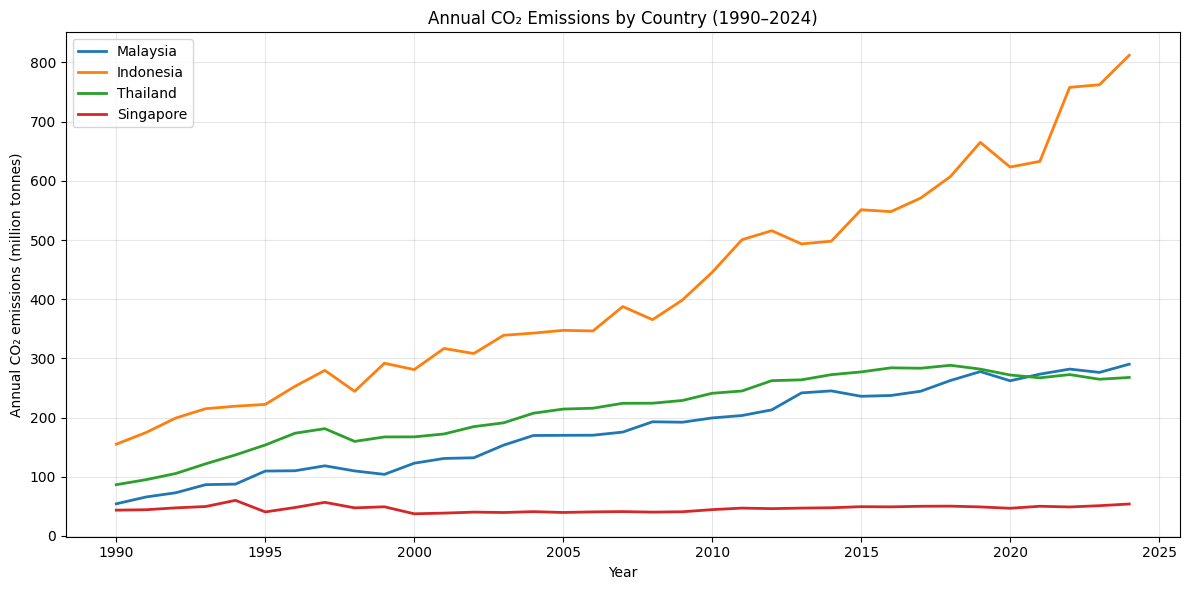

In [27]:

import matplotlib.pyplot as plt

# Prepare annual emissions data for the four countries
countries = ["Malaysia", "Indonesia", "Thailand", "Singapore"]

plot_df = recent_df[recent_df["Entity"].isin(countries)].copy()

# Convert emissions from tonnes to million tonnes
plot_df["Emissions_million_tonnes"] = (
    plot_df[emissions_col] / 1_000_000
)

# Create the line chart
plt.figure(figsize=(12, 6))

for country in countries:
    country_df = plot_df[plot_df["Entity"] == country]

    plt.plot(
        country_df["Year"],
        country_df["Emissions_million_tonnes"],
        label=country,
        linewidth=2
    )

plt.title("Annual CO₂ Emissions by Country (1990–2024)")
plt.xlabel("Year")
plt.ylabel("Annual CO₂ emissions (million tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:

# Calculate average year-on-year percentage change by country
average_yoy = (
    plot_df.groupby("Entity")["YoY_change_percent"]
    .mean()
    .reset_index(name="Average_annual_change_percent")
    .sort_values("Average_annual_change_percent", ascending=False)
)

print("Average Annual CO2 Emissions Change (1990–2024)")
print("=" * 55)
print(average_yoy.round(2).to_string(index=False))


Average Annual CO2 Emissions Change (1990–2024)
   Entity  Average_annual_change_percent
Indonesia                           5.62
 Malaysia                           5.41
 Thailand                           4.01
Singapore                           1.33


In [29]:

# Calculate correlation between year and annual CO2 emissions
correlation_results = []

for country in ["Indonesia", "Malaysia", "Thailand", "Singapore"]:
    country_df = plot_df[plot_df["Entity"] == country]

    correlation = country_df["Year"].corr(
        country_df["Emissions_million_tonnes"]
    )

    correlation_results.append({
        "Entity": country,
        "Year_Emissions_Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

print("Correlation Between Year and CO2 Emissions")
print("=" * 50)
print(correlation_df.round(3).to_string(index=False))


Correlation Between Year and CO2 Emissions
   Entity  Year_Emissions_Correlation
Indonesia                       0.977
 Malaysia                       0.992
 Thailand                       0.953
Singapore                       0.223


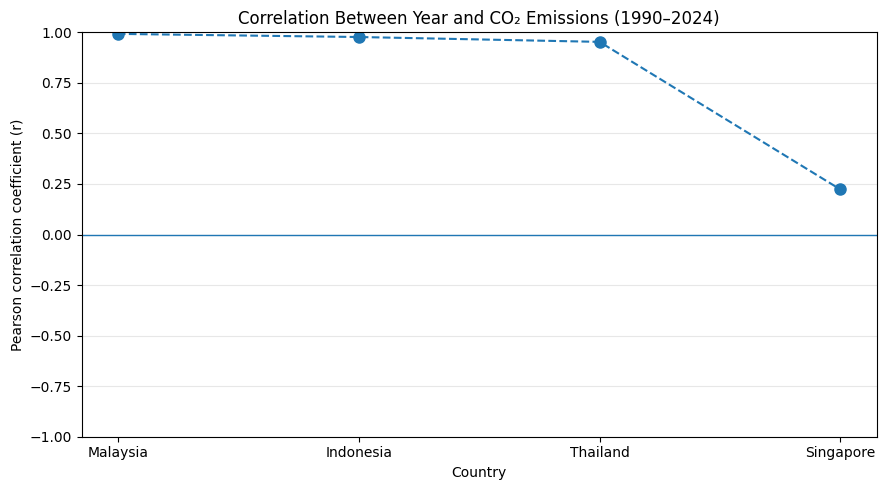

In [32]:

import matplotlib.pyplot as plt

# Sort countries by correlation
corr_plot = correlation_df.sort_values(
    "Year_Emissions_Correlation",
    ascending=False
)

# Create a dot-and-line chart
plt.figure(figsize=(9, 5))

plt.plot(
    corr_plot["Entity"],
    corr_plot["Year_Emissions_Correlation"],
    marker="o",
    linestyle="--",
    linewidth=1.5,
    markersize=8
)

plt.axhline(y=0, linewidth=1)
plt.ylim(-1, 1)
plt.ylabel("Pearson correlation coefficient (r)")
plt.xlabel("Country")
plt.title("Correlation Between Year and CO₂ Emissions (1990–2024)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
